# Proyecto final — Modelos y Simulación II

**Universidad de Antioquia · Facultad de Ingeniería**

- **Equipo:** Samuel Puerta Patiño, Simón Berrio Gaviria, Juan Estiven Carmona Muñoz
- **Grupo:** 5
- **Semestre:** 2026-2
- **Dataset:** *Financial Transactions & Fraud Detection* (Kaggle)

## Detección de fraude en transacciones financieras

**Sección 4: Entrenamiento y evaluación de los modelos**

| Apartado | Contenido |
|---|---|
| 1 | Configuración del entorno y carga de la matriz de características |
| 4.1 | Configuración experimental: partición, validación, desbalance, modelos, mallas de hiperparámetros y métricas |
| 4.2 | Resultados: efecto de los hiperparámetros, ablación por grupos de variables y desempeño en entrenamiento, validación y prueba |
| 4.3 | Conclusiones de la sección |

Este notebook usa la matriz de características que genera `01_descripcion_problema.ipynb` (`data/caracteristicas.csv`), así que ese notebook debe ejecutarse primero.

## 1. Configuración

In [1]:
from pathlib import Path
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats
from imblearn.ensemble import BalancedRandomForestClassifier
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.under_sampling import RandomUnderSampler
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, make_scorer, roc_auc_score
from sklearn.model_selection import GridSearchCV, RepeatedStratifiedKFold, train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import SVC
from sklearn.utils.class_weight import compute_sample_weight

warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

DATA_PATH = Path("../data/caracteristicas.csv")
FIG_DIR = Path("../report/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

# Paleta categórica en orden fijo (azul, naranja, aguamarina, amarillo)
COLORES_CONJUNTO = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
COLOR_REFERENCIA = "#52514e"


def savefig(name):
    plt.tight_layout()
    plt.savefig(FIG_DIR / f"{name}.pdf", bbox_inches="tight")
    plt.savefig(FIG_DIR / f"{name}.png", dpi=200, bbox_inches="tight")

In [2]:
df = pd.read_csv(DATA_PATH, parse_dates=["timestamp"])
y = df["is_fraud"].to_numpy()
print(f"Muestras: {len(df):,} | Fraudes: {y.sum()} ({100 * y.mean():.2f} %)")

Muestras: 10,000 | Fraudes: 126 (1.26 %)


## 4. Entrenamiento y evaluación de los modelos

### 4.1 Configuración experimental

#### Conjuntos de variables (estudio de ablación)

La sección 2 concluyó que, fuera de `risk_score`, ninguna variable muestra asociación con el fraude, y que `risk_score` podría contener fuga de información. Por eso cada modelo se entrena y se evalúa sobre **cuatro conjuntos de variables**, que resultan de cruzar dos factores:

| Conjunto | Variables | Pregunta que responde |
|---|---|---|
| **A. Originales** | `amount_log`, hora (sen y cos), `is_weekend` y las cuatro categóricas | ¿Hay señal en las variables originales, sin `risk_score`? |
| **B. Caracterizadas** | A + las variables de comportamiento (2.9), `anomalia_historial` (2.9.1) y `cuenta_pago_incoherente` (2.9.2) | ¿Aporta la fase de caracterización? |
| **C. Originales + risk** | A + `risk_score` | ¿Cuánto del desempeño se debe a `risk_score`? |
| **D. Caracterizadas + risk** | B + `risk_score` | Espacio completo (37 columnas) |

La comparación B frente a A mide el aporte de la caracterización, y la comparación C frente a A mide el aporte de `risk_score`.

In [3]:
ORIGINALES_NUM = ["amount_log", "hour_sin", "hour_cos"]
ORIGINALES_BIN = ["is_weekend"]
CATEGORICAS = ["account_type", "category", "payment_method", "device_type"]
CARACT_CONT = [
    "transacciones_previas", "horas_desde_anterior_log", "desvio_log_monto",
    "transacciones_24h", "transacciones_7d", "monto_7d_log", "anomalia_historial",
]
CARACT_BIN = [
    "primera_transaccion", "cambio_dispositivo", "cambio_metodo_pago",
    "cambio_categoria", "dispositivo_nuevo", "cuenta_pago_incoherente",
]

CONJUNTOS = {
    "A. Originales": dict(cont=ORIGINALES_NUM, bin=ORIGINALES_BIN),
    "B. Caracterizadas": dict(cont=ORIGINALES_NUM + CARACT_CONT, bin=ORIGINALES_BIN + CARACT_BIN),
    "C. Originales + risk": dict(cont=ORIGINALES_NUM + ["risk_score"], bin=ORIGINALES_BIN),
    "D. Caracterizadas + risk": dict(cont=ORIGINALES_NUM + CARACT_CONT + ["risk_score"], bin=ORIGINALES_BIN + CARACT_BIN),
}


def construir_preprocesador(conjunto):
    v = CONJUNTOS[conjunto]
    return ColumnTransformer([
        ("cont", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), v["cont"]),
        ("bin", make_pipeline(SimpleImputer(strategy="constant", fill_value=0), StandardScaler()), v["bin"]),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CATEGORICAS),
    ])


def columnas(conjunto):
    v = CONJUNTOS[conjunto]
    return v["cont"] + v["bin"] + CATEGORICAS


pd.DataFrame({
    nombre: {"variables de entrada": len(columnas(nombre)),
             "columnas tras codificar": construir_preprocesador(nombre).fit(df[columnas(nombre)]).transform(df[columnas(nombre)].head()).shape[1]}
    for nombre in CONJUNTOS
}).T

,variables de entrada,columnas tras codificar
A. Originales,8,23
B. Caracterizadas,21,36
C. Originales + risk,9,24
D. Caracterizadas + risk,22,37


#### Metodología de validación

- **Partición entrenamiento–prueba.** Se separa un 20 % estratificado como **conjunto de prueba** (2.000 transacciones y 25 fraudes), que no se usa en ninguna decisión hasta la evaluación final. La partición es aleatoria y no temporal porque los fraudes llegan como un proceso de Poisson, sin tendencia ni rachas (sección 2.9.2). Además, las variables de comportamiento ya usan solo información pasada de cada usuario, y ningún usuario concentra fraudes (sección 2.7).
- **Ajuste de hiperparámetros.** Sobre el 80 % de entrenamiento se hace una búsqueda en malla con **validación cruzada estratificada 5×2** (5 particiones repetidas 2 veces con distinta semilla, 10 evaluaciones por combinación). Cada partición de validación tiene unos 20 fraudes, por lo que repetir la validación cruzada reduce la varianza de la estimación. El criterio de selección es la PR-AUC media de validación.
- **Sin fuga de información.** El imputador, el escalador, el codificador y el submuestreo forman parte del `Pipeline`, así que se ajustan solo con los datos de entrenamiento de cada partición.
- **Intervalos de confianza.** En validación se reporta la media de las 10 evaluaciones con un intervalo t de Student al 95 %. Es aproximado, porque las particiones repetidas no son independientes. En prueba, el intervalo al 95 % se estima con 2.000 réplicas *bootstrap* estratificadas del conjunto de prueba.

#### Tratamiento del desbalance

Siguiendo la retroalimentación de la primera entrega, **no se usa sobremuestreo sintético (SMOTE)**: con 126 fraudes y clases que se solapan, interpolar entre fraudes generaría ejemplos poco realistas en zonas dominadas por la clase normal. En su lugar se usan dos estrategias que no inventan datos:

- **Ponderación de clases.** El error en cada fraude pesa tanto como $n_{\text{normal}}/n_{\text{fraude}} \approx 78$ errores en transacciones normales (`class_weight="balanced"` o `sample_weight` equivalente). Se usa en regresión logística, SVM, gradient boosting y la red neuronal.
- **Submuestreo de la clase mayoritaria.**
  - **Random Forest balanceado:** cada árbol se entrena con **todos los fraudes** de su muestra y un subconjunto aleatorio de transacciones normales del **mismo tamaño**, distinto en cada árbol (`BalancedRandomForestClassifier`). Así el ensamble usa todas las transacciones normales y cada árbol ve un problema balanceado.
  - **KNN:** no admite pesos de clase, así que se submuestrea la clase normal antes de buscar vecinos. La proporción fraude/normal es un hiperparámetro.

#### Modelos y mallas de hiperparámetros

Se comparan seis modelos que cubren los cinco tipos exigidos por la guía:

| Tipo exigido | Modelo | Hiperparámetro | Malla de valores |
|---|---|---|---|
| Paramétrico (regresión) | Regresión logística ponderada | `C` (inverso de la regularización L2) | 0,001; 0,01; 0,1; 1; 10 |
| No paramétrico | KNN con submuestreo | `n_neighbors` | 15; 51; 151 |
|  |  | Proporción fraude/normal tras el submuestreo | 0,1; 0,5; 1,0 |
| Ensamble de árboles | Random Forest balanceado (500 árboles) | `min_samples_leaf` | 1; 5; 20 |
|  |  | `max_features` | √p; 0,5 |
| Ensamble de árboles | Gradient boosting ponderado (`HistGradientBoosting`, 200 iteraciones) | `learning_rate` | 0,03; 0,1 |
|  |  | `max_depth` | 2; 4 |
| Red neuronal | Perceptrón multicapa ponderado (ReLU, Adam) | Capas ocultas | (16); (32, 16) |
|  |  | `alpha` (regularización L2) | 0,001; 0,1 |
| Máquina de vectores de soporte | SVM con kernel RBF ponderada | `C` | 0,1; 1; 10 |
|  |  | `gamma` | `scale`; 0,01 |

Las mallas son deliberadamente pequeñas: con unos 100 fraudes de entrenamiento, una malla grande sobreajusta la selección de hiperparámetros a las particiones de validación.

In [4]:
MODELOS = {
    "Regresión logística": dict(
        estimador=LogisticRegression(class_weight="balanced", max_iter=5000),
        malla={"modelo__C": [0.001, 0.01, 0.1, 1, 10]},
    ),
    "KNN": dict(
        estimador=KNeighborsClassifier(),
        submuestreo=True,
        malla={"modelo__n_neighbors": [15, 51, 151], "sub__sampling_strategy": [0.1, 0.5, 1.0]},
    ),
    "Random Forest balanceado": dict(
        estimador=BalancedRandomForestClassifier(
            n_estimators=500, sampling_strategy="all", replacement=True, bootstrap=False,
            random_state=RANDOM_STATE, n_jobs=1,
        ),
        malla={"modelo__min_samples_leaf": [1, 5, 20], "modelo__max_features": ["sqrt", 0.5]},
    ),
    "Gradient boosting": dict(
        estimador=HistGradientBoostingClassifier(
            max_iter=200, class_weight="balanced", early_stopping=False, random_state=RANDOM_STATE,
        ),
        malla={"modelo__learning_rate": [0.03, 0.1], "modelo__max_depth": [2, 4]},
    ),
    "Red neuronal (MLP)": dict(
        estimador=MLPClassifier(max_iter=300, random_state=RANDOM_STATE),
        pesos=True,  # sample_weight balanceado
        malla={"modelo__hidden_layer_sizes": [(16,), (32, 16)], "modelo__alpha": [0.001, 0.1]},
    ),
    "SVM (RBF)": dict(
        estimador=SVC(kernel="rbf", class_weight="balanced"),
        malla={"modelo__C": [0.1, 1, 10], "modelo__gamma": ["scale", 0.01]},
    ),
}


def construir_pipeline(nombre_modelo, conjunto):
    spec = MODELOS[nombre_modelo]
    pasos = [("pre", construir_preprocesador(conjunto))]
    if spec.get("submuestreo"):
        pasos.append(("sub", RandomUnderSampler(random_state=RANDOM_STATE)))
        return ImbPipeline(pasos + [("modelo", spec["estimador"])])
    return Pipeline(pasos + [("modelo", spec["estimador"])])

#### Métricas de desempeño

Con un 1,26 % de fraudes, la exactitud no sirve: un modelo que nunca alerta acierta el 98,7 % de las veces. Se usan métricas centradas en la clase positiva y que no dependen de fijar un umbral, porque el umbral operativo depende de cuántas alertas pueda revisar el equipo antifraude:

- **PR-AUC (precisión promedio, métrica principal).** Es el área bajo la curva precisión–exhaustividad, $\text{AP} = \sum_n (R_n - R_{n-1}) P_n$. Para un clasificador aleatorio vale la tasa de fraude (0,0126), que es la **línea base** contra la que se comparan los modelos. A diferencia de la ROC-AUC, no se infla por el gran número de verdaderos negativos [2].
- **ROC-AUC.** Es la probabilidad de que un fraude reciba un puntaje mayor que una transacción normal. Se reporta como complemento; un modelo aleatorio obtiene 0,5.
- **Exhaustividad en el 2 % de mayor puntaje (*recall@2 %*).** Es la fracción de fraudes capturados si se revisa solo el 2 % de las transacciones con mayor puntaje, que simula un presupuesto fijo de revisión [3]. Un modelo aleatorio captura el 2 %.
- **Precisión en el 2 % de mayor puntaje (*precision@2 %*).** Es la fracción de esas alertas que son fraude. Un modelo aleatorio obtiene la tasa base, 1,26 %.

In [5]:
FRACCION_ALERTAS = 0.02


def _top(y_true, puntaje):
    k = int(np.ceil(FRACCION_ALERTAS * len(y_true)))
    return np.asarray(y_true)[np.argsort(-np.asarray(puntaje), kind="stable")[:k]]


def recall_top(y_true, puntaje):
    return _top(y_true, puntaje).sum() / np.sum(y_true)


def precision_top(y_true, puntaje):
    return _top(y_true, puntaje).mean()


RESPUESTA = ("decision_function", "predict_proba")
METRICAS = {
    "pr_auc": make_scorer(average_precision_score, response_method=RESPUESTA),
    "roc_auc": make_scorer(roc_auc_score, response_method=RESPUESTA),
    "recall_2pct": make_scorer(recall_top, response_method=RESPUESTA),
    "precision_2pct": make_scorer(precision_top, response_method=RESPUESTA),
}
FUNCIONES = {"pr_auc": average_precision_score, "roc_auc": roc_auc_score,
             "recall_2pct": recall_top, "precision_2pct": precision_top}


def puntaje(modelo, X):
    final = modelo[-1]
    if hasattr(final, "decision_function"):
        return modelo.decision_function(X)
    return modelo.predict_proba(X)[:, 1]

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    df, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)
CV = RepeatedStratifiedKFold(n_splits=5, n_repeats=2, random_state=RANDOM_STATE)

pd.DataFrame({
    "transacciones": [len(y_train), len(y_test)],
    "fraudes": [y_train.sum(), y_test.sum()],
    "tasa_%": [100 * y_train.mean(), 100 * y_test.mean()],
}, index=["Entrenamiento (80 %)", "Prueba (20 %)"])

,transacciones,fraudes,tasa_%
Entrenamiento (80 %),8000,101,1.263
Prueba (20 %),2000,25,1.250


### 4.2 Resultados del entrenamiento de los modelos

Se ejecuta la búsqueda en malla para los 6 modelos y los 4 conjuntos de variables (24 búsquedas y 6.120 ajustes en total). La ejecución tarda varios minutos.

In [7]:
def ic_t(valores, confianza=0.95):
    valores = np.asarray(valores)
    media = valores.mean()
    margen = stats.t.ppf((1 + confianza) / 2, len(valores) - 1) * valores.std(ddof=1) / np.sqrt(len(valores))
    return media, media - margen, media + margen


busquedas = {}
inicio = time.time()
for conjunto in CONJUNTOS:
    Xc = X_train[columnas(conjunto)]
    for nombre_modelo, spec in MODELOS.items():
        busqueda = GridSearchCV(
            construir_pipeline(nombre_modelo, conjunto), spec["malla"], scoring=METRICAS,
            refit="pr_auc", cv=CV, n_jobs=-1, return_train_score=True,
        )
        parametros_fit = {}
        if spec.get("pesos"):
            parametros_fit["modelo__sample_weight"] = compute_sample_weight("balanced", y_train)
        busqueda.fit(Xc, y_train, **parametros_fit)
        busquedas[(nombre_modelo, conjunto)] = busqueda
    print(f"{conjunto}: listo ({time.time() - inicio:.0f} s acumulados)")

A. Originales: listo (60 s acumulados)


B. Caracterizadas: listo (120 s acumulados)


C. Originales + risk: listo (178 s acumulados)


D. Caracterizadas + risk: listo (242 s acumulados)


#### Efecto de los hiperparámetros

La Figura 6 muestra la PR-AUC de validación de cada combinación de hiperparámetros en el espacio completo con `risk_score` (conjunto D), con su intervalo de confianza al 95 %. La línea discontinua marca la PR-AUC de un clasificador aleatorio.

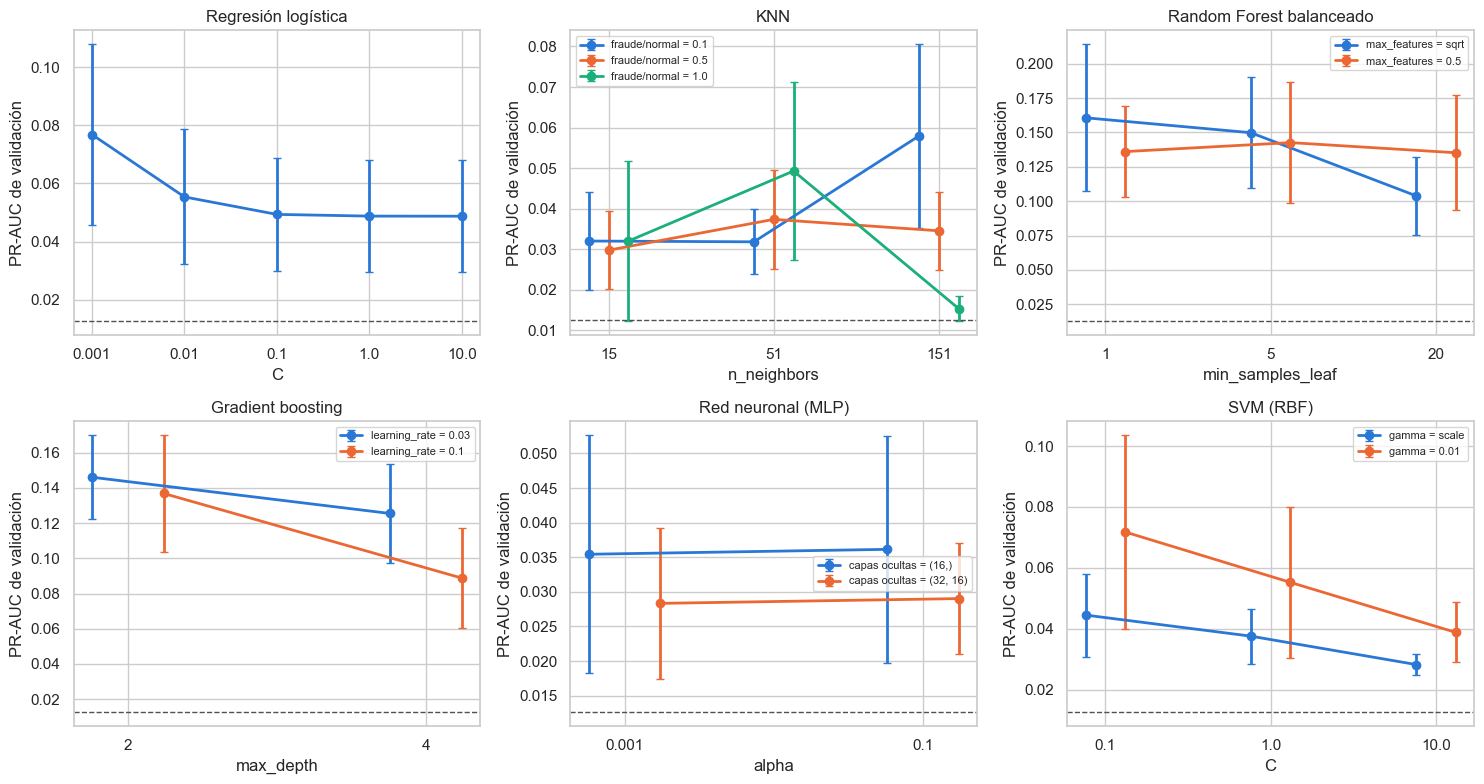

In [8]:
EJES = {  # (hiperparámetro en el eje x, hiperparámetro que distingue las series)
    "Regresión logística": ("modelo__C", None),
    "KNN": ("modelo__n_neighbors", "sub__sampling_strategy"),
    "Random Forest balanceado": ("modelo__min_samples_leaf", "modelo__max_features"),
    "Gradient boosting": ("modelo__max_depth", "modelo__learning_rate"),
    "Red neuronal (MLP)": ("modelo__alpha", "modelo__hidden_layer_sizes"),
    "SVM (RBF)": ("modelo__C", "modelo__gamma"),
}
ETIQUETAS = {
    "modelo__C": "C", "modelo__n_neighbors": "n_neighbors", "sub__sampling_strategy": "fraude/normal",
    "modelo__min_samples_leaf": "min_samples_leaf", "modelo__max_features": "max_features",
    "modelo__max_depth": "max_depth", "modelo__learning_rate": "learning_rate",
    "modelo__alpha": "alpha", "modelo__hidden_layer_sizes": "capas ocultas", "modelo__gamma": "gamma",
}
N_SPLITS = CV.get_n_splits()


def tabla_cv(busqueda, metrica="pr_auc"):
    res = pd.DataFrame(busqueda.cv_results_)
    divisiones = res[[f"split{i}_test_{metrica}" for i in range(N_SPLITS)]].to_numpy()
    ic = np.array([ic_t(fila) for fila in divisiones])
    params = pd.DataFrame(list(res["params"])).astype(str)
    return params.assign(media=ic[:, 0], inf=ic[:, 1], sup=ic[:, 2])


CONJUNTO_PRINCIPAL = "D. Caracterizadas + risk"
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, (nombre_modelo, (x, serie)) in zip(axes.ravel(), EJES.items()):
    t = tabla_cv(busquedas[(nombre_modelo, CONJUNTO_PRINCIPAL)])
    grupos = [(None, t)] if serie is None else list(t.groupby(serie, sort=False))
    desplaz = np.linspace(-0.12, 0.12, len(grupos)) if len(grupos) > 1 else [0]
    for color, d, (valor, g) in zip(COLORES_CONJUNTO, desplaz, grupos):
        pos = np.arange(len(g)) + d
        ax.errorbar(pos, g["media"], yerr=[g["media"] - g["inf"], g["sup"] - g["media"]],
                    fmt="-o", ms=6, lw=2, capsize=3, color=color,
                    label=None if valor is None else f"{ETIQUETAS[serie]} = {valor}")
    ax.set_xticks(range(len(grupos[0][1])), grupos[0][1][x])
    ax.axhline(y_train.mean(), color=COLOR_REFERENCIA, ls="--", lw=1)
    ax.set_title(nombre_modelo)
    ax.set_xlabel(ETIQUETAS[x])
    ax.set_ylabel("PR-AUC de validación")
    if serie is not None:
        ax.legend(fontsize=8, loc="best")
savefig("fig_hiperparametros")
plt.show()

*Figura 6. PR-AUC de validación (media e intervalo de confianza al 95 % de la validación cruzada 5×2) para cada combinación de hiperparámetros en el conjunto D (todas las variables, incluido `risk_score`). La línea discontinua es la PR-AUC de un clasificador aleatorio (tasa de fraude).*

#### Ablación por grupos de variables

La Figura 7 compara la mejor configuración de cada modelo en los cuatro conjuntos de variables. Es el resultado central de la sección: muestra de dónde viene el desempeño.

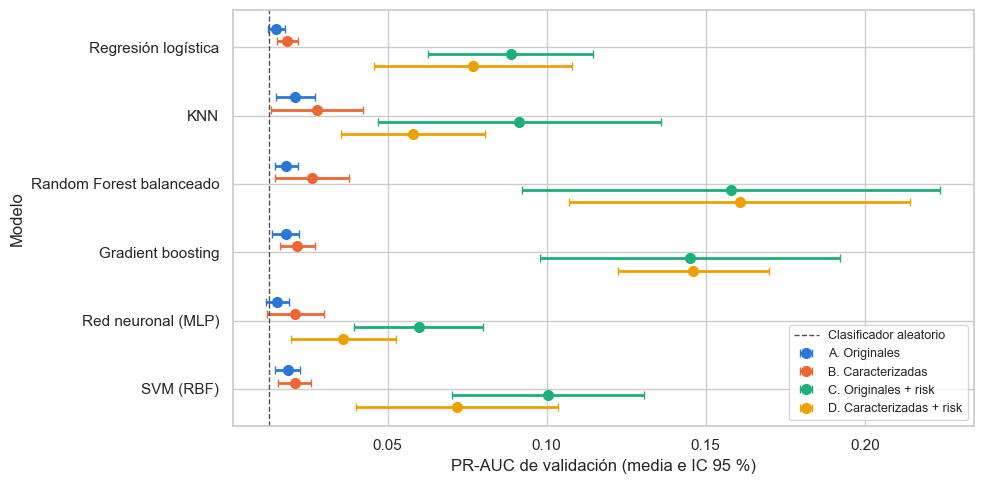

In [9]:
filas = []
for (nombre_modelo, conjunto), busqueda in busquedas.items():
    i = busqueda.best_index_
    fila = {"modelo": nombre_modelo, "conjunto": conjunto,
            "mejores_hiperparámetros": {k.split("__")[1]: v for k, v in busqueda.best_params_.items()}}
    for m in METRICAS:
        divisiones = [busqueda.cv_results_[f"split{s}_test_{m}"][i] for s in range(N_SPLITS)]
        fila[f"val_{m}"], fila[f"val_{m}_inf"], fila[f"val_{m}_sup"] = ic_t(divisiones)
    filas.append(fila)
validacion = pd.DataFrame(filas)

orden_modelos = list(MODELOS)
fig, ax = plt.subplots(figsize=(10, 5))
for j, (conjunto, color) in enumerate(zip(CONJUNTOS, COLORES_CONJUNTO)):
    t = validacion[validacion["conjunto"] == conjunto].set_index("modelo").loc[orden_modelos]
    pos = np.arange(len(orden_modelos)) + (j - 1.5) * 0.18
    ax.errorbar(t["val_pr_auc"], pos,
                xerr=[t["val_pr_auc"] - t["val_pr_auc_inf"], t["val_pr_auc_sup"] - t["val_pr_auc"]],
                fmt="o", ms=7, lw=2, capsize=3, color=color, label=conjunto)
ax.axvline(y_train.mean(), color=COLOR_REFERENCIA, ls="--", lw=1, label="Clasificador aleatorio")
ax.set_yticks(range(len(orden_modelos)), orden_modelos)
ax.invert_yaxis()
ax.set_xlabel("PR-AUC de validación (media e IC 95 %)")
ax.set_ylabel("Modelo")
ax.legend(loc="lower right", fontsize=9)
savefig("fig_ablacion")
plt.show()

*Figura 7. PR-AUC de validación de la mejor configuración de cada modelo en los cuatro conjuntos de variables. A: variables originales sin `risk_score`; B: A más las variables de la fase de caracterización; C: A más `risk_score`; D: todas. La línea discontinua es la PR-AUC de un clasificador aleatorio.*

In [10]:
tabla_val = validacion.pivot(index="modelo", columns="conjunto", values="val_pr_auc").loc[orden_modelos]
tabla_val["Aporte de la caracterización (B − A)"] = tabla_val["B. Caracterizadas"] - tabla_val["A. Originales"]
tabla_val["Aporte de risk_score (C − A)"] = tabla_val["C. Originales + risk"] - tabla_val["A. Originales"]

# Referencia: risk_score usado directamente como puntaje, en las mismas particiones de validación
ref_val = [average_precision_score(y_train[va], X_train["risk_score"].to_numpy()[va]) for _, va in CV.split(X_train, y_train)]
print(f"PR-AUC de un clasificador aleatorio: {y_train.mean():.4f}")
print("PR-AUC de risk_score como puntaje directo (sin modelo): {:.3f} [IC 95 %: {:.3f}, {:.3f}]".format(*ic_t(ref_val)))
tabla_val

PR-AUC de un clasificador aleatorio: 0.0126
PR-AUC de risk_score como puntaje directo (sin modelo): 0.161 [IC 95 %: 0.126, 0.197]


conjunto,A. Originales,B. Caracterizadas,C. Originales + risk,D. Caracterizadas + risk,Aporte de la caracterización (B − A),Aporte de risk_score (C − A)
modelo,,,,,,
Regresión logística,0.015,0.019,0.089,0.077,0.003,0.074
KNN,0.021,0.028,0.091,0.058,0.007,0.070
Random Forest balanceado,0.018,0.026,0.158,0.161,0.008,0.140
Gradient boosting,0.018,0.022,0.145,0.146,0.004,0.127
Red neuronal (MLP),0.015,0.021,0.060,0.036,0.006,0.044
SVM (RBF),0.019,0.021,0.100,0.072,0.002,0.082


#### Desempeño en entrenamiento, validación y prueba

Para cada modelo se toma la mejor configuración de validación, se reentrena con todo el conjunto de entrenamiento y se evalúa **una sola vez** en el conjunto de prueba. Se reportan los conjuntos D (todas las variables) y B (todas excepto `risk_score`).

In [11]:
def bootstrap_ic(y_true, s, funcion, replicas=2000, semilla=RANDOM_STATE):
    rng = np.random.default_rng(semilla)
    pos, neg = np.flatnonzero(y_true == 1), np.flatnonzero(y_true == 0)
    valores = []
    for _ in range(replicas):
        idx = np.concatenate([rng.choice(pos, len(pos)), rng.choice(neg, len(neg))])
        valores.append(funcion(y_true[idx], s[idx]))
    return np.percentile(valores, [2.5, 97.5])


filas = []
puntajes_prueba = {}
for (nombre_modelo, conjunto), busqueda in busquedas.items():
    if conjunto not in ("B. Caracterizadas", "D. Caracterizadas + risk"):
        continue
    modelo = busqueda.best_estimator_
    s_train = puntaje(modelo, X_train[columnas(conjunto)])
    s_test = puntaje(modelo, X_test[columnas(conjunto)])
    puntajes_prueba[(nombre_modelo, conjunto)] = s_test
    i = busqueda.best_index_
    for m, f in FUNCIONES.items():
        inf, sup = bootstrap_ic(y_test, s_test, f)
        filas.append({
            "conjunto": conjunto, "modelo": nombre_modelo, "métrica": m,
            "entrenamiento": f(y_train, s_train),
            "validación": busqueda.cv_results_[f"mean_test_{m}"][i],
            "prueba": f(y_test, s_test),
            "prueba_IC95": f"[{inf:.3f}, {sup:.3f}]",
        })
resultados = pd.DataFrame(filas)

# Referencia: risk_score usado directamente como puntaje, sin modelo
s_ref = X_test["risk_score"].to_numpy()
referencia = pd.DataFrame([
    {"métrica": m, "prueba": f(y_test, s_ref),
     "prueba_IC95": "[{:.3f}, {:.3f}]".format(*bootstrap_ic(y_test, s_ref, f))}
    for m, f in FUNCIONES.items()
]).set_index("métrica")
print("Referencia: risk_score como puntaje directo (sin modelo)")
display(referencia)
resultados[resultados["métrica"] == "pr_auc"].set_index(["conjunto", "modelo"]).drop(columns="métrica")

Referencia: risk_score como puntaje directo (sin modelo)


,prueba,prueba_IC95
métrica,,
pr_auc,0.028,"[0.012, 0.098]"
roc_auc,0.473,"[0.332, 0.615]"
recall_2pct,0.120,"[0.000, 0.280]"
precision_2pct,0.075,"[0.000, 0.175]"


entrenamiento  validación  \
conjunto                 modelo                                                
B. Caracterizadas        Regresión logística               0.024       0.019   
                         KNN                               0.030       0.028   
                         Random Forest balanceado          0.455       0.026   
                         Gradient boosting                 0.590       0.022   
                         Red neuronal (MLP)                0.451       0.021   
                         SVM (RBF)                         0.081       0.021   
D. Caracterizadas + risk Regresión logística               0.073       0.077   
                         KNN                               0.055       0.058   
                         Random Forest balanceado          0.941       0.161   
                         Gradient boosting                 0.227       0.146   
                         Red neuronal (MLP)                0.427       0.036   
                         SVM (RBF)                         0.091       0.072   

                                                   prueba     prueba_IC95  
conjunto                 modelo                                            
B. Caracterizadas        Regresión logística        0.016  [0.010, 0.038]  
                         KNN                        0.019  [0.011, 0.054]  
                         Random Forest balanceado   0.018  [0.011, 0.038]  
                         Gradient boosting          0.014  [0.010, 0.034]  
                         Red neuronal (MLP)         0.014  [0.009, 0.039]  
                         SVM (RBF)                  0.013  [0.010, 0.022]  
D. Caracterizadas + risk Regresión logística        0.014  [0.011, 0.025]  
                         KNN                        0.015  [0.012, 0.025]  
                         Random Forest balanceado   0.028  [0.014, 0.079]  
                         Gradient boosting          0.041  [0.012, 0.151]  
                         Red neuronal (MLP)         0.011  [0.009, 0.016]  
                         SVM (RBF)                  0.016  [0.012, 0.028]

In [12]:
(resultados[resultados["conjunto"] == "D. Caracterizadas + risk"]
 .pivot(index="modelo", columns="métrica", values=["validación", "prueba"])
 .loc[orden_modelos])

validación                                    prueba  \
métrica                      pr_auc precision_2pct recall_2pct roc_auc pr_auc   
modelo                                                                          
Regresión logística           0.077          0.081       0.128   0.645  0.014   
KNN                           0.058          0.066       0.104   0.612  0.015   
Random Forest balanceado      0.161          0.184       0.292   0.635  0.028   
Gradient boosting             0.146          0.169       0.267   0.623  0.041   
Red neuronal (MLP)            0.036          0.041       0.064   0.553  0.011   
SVM (RBF)                     0.072          0.072       0.114   0.648  0.016   

                                                             
métrica                  precision_2pct recall_2pct roc_auc  
modelo                                                       
Regresión logística               0.000       0.000   0.498  
KNN                               0.000       0.000   0.557  
Random Forest balanceado          0.075       0.120   0.552  
Gradient boosting                 0.075       0.120   0.486  
Red neuronal (MLP)                0.000       0.000   0.443  
SVM (RBF)                         0.000       0.000   0.552

#### ¿Qué tan representativa es la partición de prueba?

El conjunto de prueba solo tiene 25 fraudes, así que su resultado depende mucho de *cuáles* fraudes cayeron en él. En la sección 2.4 se vio que solo cerca de una cuarta parte de los fraudes tiene `risk_score` alto. Por eso se revisa cuántos de ellos quedaron en cada partición y qué tan típica es esta partición frente a otras particiones aleatorias posibles. La partición **no se cambia**: elegir la semilla según el resultado en prueba sería usar el conjunto de prueba para tomar decisiones.

In [13]:
UMBRAL_RIESGO = 65
filas = []
for nombre, X_, y_ in [("Entrenamiento", X_train, y_train), ("Prueba", X_test, y_test)]:
    alto = X_.loc[y_ == 1, "risk_score"] >= UMBRAL_RIESGO
    filas.append({"partición": nombre, "fraudes": int(y_.sum()),
                  f"fraudes con risk_score ≥ {UMBRAL_RIESGO}": int(alto.sum()), "fracción_%": 100 * alto.mean()})
display(pd.DataFrame(filas).set_index("partición"))

# PR-AUC de risk_score (sin modelo) en la partición de prueba de 200 particiones aleatorias alternativas
pr_auc_alternativas = []
for semilla in range(200):
    _, X_alt, _, y_alt = train_test_split(df, y, test_size=0.2, stratify=y, random_state=semilla)
    pr_auc_alternativas.append(average_precision_score(y_alt, X_alt["risk_score"]))
pr_auc_alternativas = np.array(pr_auc_alternativas)
pr_auc_actual = average_precision_score(y_test, X_test["risk_score"])
pd.Series({
    "PR-AUC de risk_score en la prueba usada": round(pr_auc_actual, 3),
    "Mediana en 200 particiones alternativas": round(np.median(pr_auc_alternativas), 3),
    "Percentiles 5 y 95 de las alternativas": "{:.3f} – {:.3f}".format(*np.percentile(pr_auc_alternativas, [5, 95])),
    "Percentil de la partición usada": round(100 * (pr_auc_alternativas < pr_auc_actual).mean(), 1),
}, dtype=object).to_frame("valor")

,fraudes,fraudes con risk_score ≥ 65,fracción_%
partición,,,
Entrenamiento,101,27,26.733
Prueba,25,3,12.000


,valor
PR-AUC de risk_score en la prueba usada,0.028
Mediana en 200 particiones alternativas,0.108
Percentiles 5 y 95 de las alternativas,0.040 – 0.207
Percentil de la partición usada,1.500


La partición de prueba es **atípica**. Tiene proporcionalmente menos fraudes con `risk_score` alto que el entrenamiento, y la PR-AUC de `risk_score` en ella está en la cola inferior de las particiones posibles. Por eso el desempeño en prueba de los modelos con `risk_score` subestima su desempeño esperado. Para tener una estimación que no dependa de una sola partición, se complementa con una **validación cruzada anidada**.

#### Estimación robusta: validación cruzada anidada

La validación cruzada anidada tiene dos bucles:

- El bucle **externo** (5 particiones × 2 repeticiones sobre las 10.000 transacciones) estima el desempeño de generalización.
- El bucle **interno** (validación cruzada estratificada de 3 particiones, dentro de cada partición externa de entrenamiento) selecciona los hiperparámetros con la misma malla.

Así, cada transacción se usa como prueba una vez por repetición, la selección de hiperparámetros nunca ve los datos con los que se evalúa y el resultado promedia 10 conjuntos de prueba en lugar de uno. Se aplica a los conjuntos B (sin `risk_score`) y D (con `risk_score`).

In [14]:
from sklearn.model_selection import StratifiedKFold, cross_validate

CV_EXTERNA = RepeatedStratifiedKFold(n_splits=5, n_repeats=2, random_state=RANDOM_STATE + 1)
CV_INTERNA = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)

anidada = {}
inicio = time.time()
for conjunto in ["B. Caracterizadas", "D. Caracterizadas + risk"]:
    Xc = df[columnas(conjunto)]
    for nombre_modelo, spec in MODELOS.items():
        interna = GridSearchCV(construir_pipeline(nombre_modelo, conjunto), spec["malla"],
                               scoring="average_precision", cv=CV_INTERNA, n_jobs=-1)
        params = {"modelo__sample_weight": compute_sample_weight("balanced", y)} if spec.get("pesos") else None
        anidada[(nombre_modelo, conjunto)] = cross_validate(interna, Xc, y, cv=CV_EXTERNA, scoring=METRICAS, params=params)
    print(f"{conjunto}: listo ({time.time() - inicio:.0f} s acumulados)")

# Referencia sin modelo en las mismas particiones externas
ref_anidada = {m: [f(y[te], df["risk_score"].to_numpy()[te]) for _, te in CV_EXTERNA.split(df, y)]
               for m, f in FUNCIONES.items()}

B. Caracterizadas: listo (251 s acumulados)


D. Caracterizadas + risk: listo (483 s acumulados)


In [15]:
def resumen_anidada(valores):
    media, inf, sup = ic_t(valores)
    return f"{media:.3f} [{inf:.3f}, {sup:.3f}]"


filas = []
for (nombre_modelo, conjunto), r in anidada.items():
    filas.append({"conjunto": conjunto, "modelo": nombre_modelo,
                  **{m: resumen_anidada(r[f"test_{m}"]) for m in METRICAS}})
filas.append({"conjunto": "Referencia", "modelo": "risk_score sin modelo",
              **{m: resumen_anidada(v) for m, v in ref_anidada.items()}})
filas.append({"conjunto": "Referencia", "modelo": "Clasificador aleatorio",
              "pr_auc": f"{y.mean():.3f}", "roc_auc": "0.500",
              "recall_2pct": f"{FRACCION_ALERTAS:.3f}", "precision_2pct": f"{y.mean():.3f}"})
print("Media e intervalo de confianza al 95 % sobre las 10 particiones externas")
tabla_anidada = pd.DataFrame(filas).set_index(["conjunto", "modelo"])
tabla_anidada

Media e intervalo de confianza al 95 % sobre las 10 particiones externas


pr_auc  \
conjunto                 modelo                                           
B. Caracterizadas        Regresión logística       0.018 [0.014, 0.022]   
                         KNN                       0.016 [0.013, 0.019]   
                         Random Forest balanceado  0.021 [0.009, 0.032]   
                         Gradient boosting         0.016 [0.013, 0.020]   
                         Red neuronal (MLP)        0.019 [0.014, 0.024]   
                         SVM (RBF)                 0.016 [0.014, 0.018]   
D. Caracterizadas + risk Regresión logística       0.047 [0.032, 0.061]   
                         KNN                       0.032 [0.026, 0.037]   
                         Random Forest balanceado  0.116 [0.069, 0.164]   
                         Gradient boosting         0.110 [0.064, 0.156]   
                         Red neuronal (MLP)        0.026 [0.018, 0.033]   
                         SVM (RBF)                 0.052 [0.033, 0.070]   
Referencia               risk_score sin modelo     0.121 [0.080, 0.162]   
                         Clasificador aleatorio                   0.013   

                                                                roc_auc  \
conjunto                 modelo                                           
B. Caracterizadas        Regresión logística       0.523 [0.475, 0.572]   
                         KNN                       0.535 [0.508, 0.562]   
                         Random Forest balanceado  0.531 [0.502, 0.561]   
                         Gradient boosting         0.530 [0.481, 0.578]   
                         Red neuronal (MLP)        0.512 [0.466, 0.557]   
                         SVM (RBF)                 0.530 [0.486, 0.574]   
D. Caracterizadas + risk Regresión logística       0.614 [0.549, 0.678]   
                         KNN                       0.615 [0.585, 0.644]   
                         Random Forest balanceado  0.613 [0.573, 0.653]   
                         Gradient boosting         0.603 [0.557, 0.648]   
                         Red neuronal (MLP)        0.538 [0.504, 0.572]   
                         SVM (RBF)                 0.626 [0.568, 0.684]   
Referencia               risk_score sin modelo     0.603 [0.541, 0.665]   
                         Clasificador aleatorio                   0.500   

                                                             recall_2pct  \
conjunto                 modelo                                            
B. Caracterizadas        Regresión logística        0.032 [0.009, 0.054]   
                         KNN                        0.040 [0.010, 0.069]   
                         Random Forest balanceado   0.024 [0.004, 0.044]   
                         Gradient boosting         0.016 [-0.012, 0.044]   
                         Red neuronal (MLP)         0.036 [0.015, 0.057]   
                         SVM (RBF)                 0.016 [-0.004, 0.036]   
D. Caracterizadas + risk Regresión logística        0.099 [0.072, 0.126]   
                         KNN                        0.091 [0.065, 0.117]   
                         Random Forest balanceado   0.254 [0.190, 0.318]   
                         Gradient boosting          0.234 [0.169, 0.300]   
                         Red neuronal (MLP)         0.052 [0.032, 0.071]   
                         SVM (RBF)                  0.107 [0.067, 0.146]   
Referencia               risk_score sin modelo      0.238 [0.171, 0.306]   
                         Clasificador aleatorio                    0.020   

                                                          precision_2pct  
conjunto                 modelo                                           
B. Caracterizadas        Regresión logística        0.020 [0.006, 0.034]  
                         KNN                        0.025 [0.006, 0.044]  
                         Random Forest balanceado   0.015 [0.002, 0.028]  
                         Gradient boosting         0.010 [-0.007, 0.027

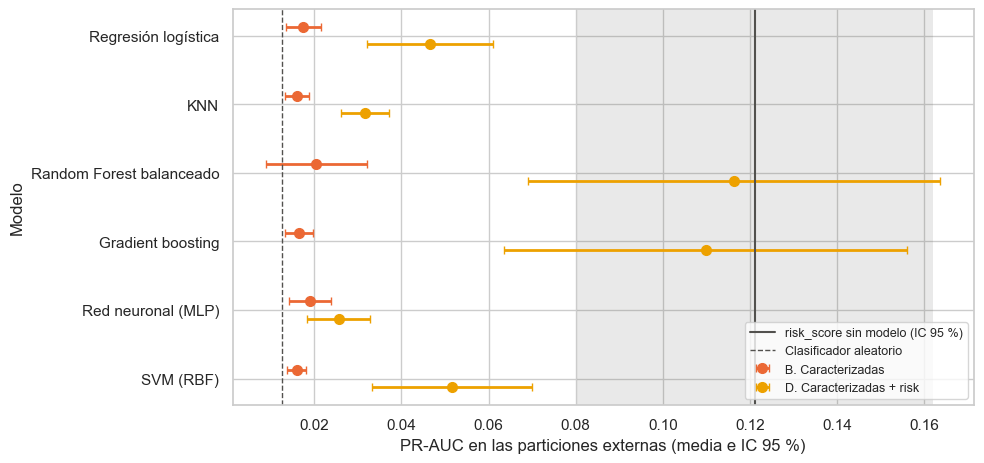

In [16]:
fig, ax = plt.subplots(figsize=(10, 4.8))
for j, (conjunto, color) in enumerate(zip(["B. Caracterizadas", "D. Caracterizadas + risk"],
                                          [COLORES_CONJUNTO[1], COLORES_CONJUNTO[3]])):
    medias, errores = [], [[], []]
    for nombre_modelo in orden_modelos:
        media, inf, sup = ic_t(anidada[(nombre_modelo, conjunto)]["test_pr_auc"])
        medias.append(media)
        errores[0].append(media - inf)
        errores[1].append(sup - media)
    pos = np.arange(len(orden_modelos)) + (j - 0.5) * 0.25
    ax.errorbar(medias, pos, xerr=errores, fmt="o", ms=7, lw=2, capsize=3, color=color, label=conjunto)
ref_media, ref_inf, ref_sup = ic_t(ref_anidada["pr_auc"])
ax.axvspan(ref_inf, ref_sup, color=COLOR_REFERENCIA, alpha=0.12, lw=0)
ax.axvline(ref_media, color=COLOR_REFERENCIA, lw=1.5, label="risk_score sin modelo (IC 95 %)")
ax.axvline(y.mean(), color=COLOR_REFERENCIA, ls="--", lw=1, label="Clasificador aleatorio")
ax.set_yticks(range(len(orden_modelos)), orden_modelos)
ax.invert_yaxis()
ax.set_xlabel("PR-AUC en las particiones externas (media e IC 95 %)")
ax.set_ylabel("Modelo")
ax.legend(loc="lower right", fontsize=9)
savefig("fig_cv_anidada")
plt.show()

*Figura 8. PR-AUC estimada con validación cruzada anidada (10 particiones externas) para los conjuntos B (sin `risk_score`) y D (con `risk_score`). La línea continua y la franja gris muestran `risk_score` usado directamente como puntaje, sin modelo; la línea discontinua es un clasificador aleatorio.*

### 4.3 Conclusiones de la sección

1. **Sin `risk_score` ningún modelo supera de forma apreciable al azar.** Con las variables originales (A) y con las de la fase de caracterización (B), la PR-AUC de validación de los seis modelos está entre 0,015 y 0,028, frente a 0,0126 de un clasificador aleatorio. En la validación cruzada anidada, el conjunto B obtiene una PR-AUC entre 0,016 y 0,021 y una ROC-AUC entre 0,51 y 0,54. Esto confirma, ahora con modelos que combinan todas las variables y sus interacciones, la conclusión de las secciones 2.9 a 2.9.2: el problema no está en el modelo ni en la ingeniería de características, sino en que los datos no contienen información sobre el fraude fuera de `risk_score`.

2. **La fase de caracterización aporta poco, aunque de forma consistente.** El aporte de B frente a A es de +0,002 a +0,008 en PR-AUC de validación, en la misma dirección para los seis modelos pero dentro del margen de ruido. Es decir, las variables de historial, incluido el puntaje de anomalía recomendado tras la primera entrega, se evaluaron formalmente y no cambian el desempeño de manera relevante.

3. **Todo el desempeño útil proviene de `risk_score`.** Agregarlo (C frente a A) aumenta la PR-AUC de validación entre 0,04 y 0,14. Los dos mejores modelos son el **Random Forest balanceado** (PR-AUC de validación 0,161; validación cruzada anidada 0,116 [0,069; 0,164]) y el **gradient boosting ponderado** (0,146 y 0,110 [0,064; 0,156]). Ambos capturan cerca del 25 % de los fraudes revisando solo el 2 % de las transacciones, frente al 2 % que capturaría una revisión al azar. Sin embargo, **ninguno supera a `risk_score` usado directamente como puntaje**, sin modelo (0,161 en validación y 0,121 [0,080; 0,162] en la validación anidada). En la práctica, los mejores modelos aprenden a ordenar las transacciones por `risk_score`. Como esta variable podría contener fuga de información (sección 2.4), este desempeño debe interpretarse con cautela.

4. **Las variables sin señal perjudican a los modelos más sensibles al ruido.** En regresión logística, KNN, SVM y la red neuronal, el conjunto D rinde menos que el C: las 13 columnas adicionales, que no tienen señal, diluyen la de `risk_score`. Los modelos de árboles no se ven afectados porque eligen las variables en cada división. Este resultado motiva el análisis de relevancia y la reducción de dimensión de la sección 5.

5. **Se prefieren configuraciones muy regularizadas**, como corresponde a una señal débil: C = 0,001 en la regresión logística, árboles de profundidad 2 con tasa de aprendizaje 0,03 en el gradient boosting y `gamma` = 0,01 con C = 0,1 en la SVM (Figura 6). Aun así, los modelos flexibles sobreajustan: el Random Forest alcanza una PR-AUC de 0,94 en entrenamiento frente a 0,16 en validación, y la red neuronal 0,43 frente a 0,04.

6. **El conjunto de prueba es atípico y su resultado debe leerse junto con la validación anidada.** Solo 3 de sus 25 fraudes (12 %) tienen `risk_score` alto, frente al 27 % en entrenamiento. La PR-AUC de `risk_score` en esta partición (0,028) está en el percentil 1,5 de 200 particiones alternativas. Por eso la PR-AUC en prueba del Random Forest (0,028) y del gradient boosting (0,041) es mucho menor que en validación. Esta diferencia no se debe al sobreajuste de los hiperparámetros: `risk_score` sin modelo cae exactamente en la misma proporción. La validación cruzada anidada, que promedia 10 particiones de prueba, es la estimación más fiable del desempeño esperado.

7. **Tratamiento del desbalance.** Siguiendo la retroalimentación recibida, se usaron la ponderación de clases y el submuestreo por árbol en lugar de SMOTE. El Random Forest balanceado, que entrena cada árbol con todos los fraudes y una muestra del mismo tamaño de transacciones normales, fue el mejor modelo, junto con el gradient boosting ponderado. **Estos dos modelos son los que se evaluarán en la sección 5.**